In [1]:
train_path = 'imagenette2-320/train'

In [2]:
import os
import glob
from PIL import Image

total_images = len(list(glob.glob(os.path.join(train_path, '*/*.JPEG'))))
print(f"total images: {total_images}")

total images: 9469


In [3]:
sample_image_path = glob.glob(os.path.join(train_path, '*/*.JPEG'))[0]
with Image.open(sample_image_path) as img:
    width, height = img.size

In [4]:
width

480

In [5]:
height

320

In [6]:
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

import tensorflow as tf
from keras.layers import Input
from keras.models import Model, Sequential
from keras.layers import (
    Reshape,
    Dense,
    Dropout,
    Flatten,
    Input,
    LeakyReLU,
    ReLU,
    BatchNormalization,
    Conv2DTranspose,
    Conv2D,
    MaxPooling2D,
    concatenate,
    GlobalAveragePooling2D,
    UpSampling2D,
    Activation,
    Add
)
from keras.datasets import mnist
from keras.optimizers import Adam
from tensorflow.keras import backend as K

2026-07-05 13:24:37.046543: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1783250677.064780   28846 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1783250677.070237   28846 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-07-05 13:24:37.088602: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [7]:
gpus = tf.config.experimental.list_physical_devices('GPU')

if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("Memory growth enabled for GPU")
    except RuntimeError as e:
        print(f"Error setting memory growth: {e}")

Memory growth enabled for GPU


In [8]:
train_path = 'imagenette2-320/train'
BATCH_SIZE = 128
IMG_SIZE = (192, 192)

In [9]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    labels=None,
    color_mode='rgb',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

Found 9469 files.


I0000 00:00:1783250682.841756   28846 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 7101 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1070, pci bus id: 0000:01:00.0, compute capability: 6.1


In [10]:
def preprocess_data(color_batch):
    normalized_batch = tf.cast(color_batch, tf.float32)
    normalized_batch = (normalized_batch - 127.5) / 127.5
    grayscale_batch = tf.image.rgb_to_grayscale(normalized_batch)
    return grayscale_batch, normalized_batch

In [11]:
train_generator = train_ds.map(preprocess_data, num_parallel_calls=tf.data.AUTOTUNE)
train_generator = train_generator.cache().shuffle(buffer_size=1000).prefetch(buffer_size=tf.data.AUTOTUNE)

In [12]:
# Generator

inputs = Input(shape=(192, 192, 1))

# --- Encoder (Downsampling) ---

# 192x192 -> 96x96
conv1 = Conv2D(16, (4, 4), strides=2, padding='same')(inputs)
conv1 = BatchNormalization()(conv1)
conv1 = Activation('relu')(conv1)

# 96x96 -> 48x48
conv2 = Conv2D(32, (4, 4), strides=2, padding='same')(conv1)
conv2 = BatchNormalization()(conv2)
conv2 = Activation('relu')(conv2)

# 48x48 -> 24x24
conv3 = Conv2D(64, (4, 4), strides=2, padding='same')(conv2)
conv3 = BatchNormalization()(conv3)
conv3 = Activation('relu')(conv3)

# --- Bottleneck ---
# 24x24 -> 12x12
bottleneck = Conv2D(128, (4, 4), strides=2, padding='same')(conv3)
bottleneck = BatchNormalization()(bottleneck)
bottleneck = Activation('relu')(bottleneck)


# --- Decoder (Upsampling) ---
# 12x12 -> 24x24
up1 = Conv2DTranspose(64, (4, 4), strides=2, padding='same')(bottleneck)
up1 = BatchNormalization()(up1)
up1 = Activation('relu')(up1)
concat1 = concatenate([up1, conv3])

# 24x24 -> 48x48
up2 = Conv2DTranspose(32, (4, 4), strides=2, padding='same')(concat1)
up2 = BatchNormalization()(up2)
up2 = Activation('relu')(up2)
concat2 = concatenate([up2, conv2])

# 48x48 -> 96x96
up3 = Conv2DTranspose(16, (4, 4), strides=2, padding='same')(concat2)
up3 = BatchNormalization()(up3)
up3 = Activation('relu')(up3)
concat3 = concatenate([up3, conv1])

# 96x96 -> 192x192
up4 = Conv2DTranspose(16, (4, 4), strides=2, padding='same')(concat3)
up4 = BatchNormalization()(up4)
up4 = Activation('relu')(up4)

output = Conv2D(3, (4, 4), padding='same', activation='tanh')(up4)

generator = Model(inputs=[inputs], outputs=[output])
generator.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 192, 192,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 96, 96,    │        272 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 96, 96,    │         64 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 96, 96,    │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 48, 48,    │      8,224 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 48, 48,    │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 48, 48,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 24, 24,    │     32,832 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 24, 24,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 24, 24,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 12, 12,    │    131,200 │ activation_2[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 12, 12,    │        512 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 12, 12,    │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 24, 24,    │    131,136 │ activation_3[0][… │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 24, 24,    │        256 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 24, 24,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 24, 24,    │          0 │ activation_4[0][

 Total params: 396,083 (1.51 MB)

 Trainable params: 395,347 (1.51 MB)

 Non-trainable params: 736 (2.88 KB)

In [13]:
# Discriminator Network
input_image = Input(shape=(192, 192, 1), name='input_image')

target_image = Input(shape=(192, 192, 3), name='target_image')

x = concatenate([input_image, target_image])  # Shape: (256, 256, 4)

x = Conv2D(16, (3, 3), strides=(2, 2), padding='same')(x)
x = BatchNormalization()(x)
x = LeakyReLU(0.2)(x)

x = Conv2D(32, (3, 3), strides=(2, 2), padding='same')(x)
x = BatchNormalization()(x)
x = LeakyReLU(0.2)(x)

x = Conv2D(128, (3, 3), strides=(2, 2), padding='same')(x)
x = BatchNormalization()(x)
x = LeakyReLU(0.2)(x)

x = Conv2D(128, (3, 3), strides=(2, 2), padding='same')(x)
x = BatchNormalization()(x)
x = LeakyReLU(0.2)(x)

validity = Conv2D(1, (3, 3), strides=(1, 1), padding='same', activation='sigmoid')(x)

discriminator = Model([input_image, target_image], validity, name='discriminator')

discriminator.summary()

Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 192, 192,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ target_image        │ (None, 192, 192,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 192, 192,  │          0 │ input_image[0][0… │
│ (Concatenate)       │ 4)                │            │ target_image[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 96, 96,    │        592 │ concatenate_3[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 96, 96,    │         64 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu         │ (None, 96, 96,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 48, 48,    │      4,640 │ leaky_re_lu[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 48, 48,    │        128 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_1       │ (None, 48, 48,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 24, 24,    │     36,992 │ leaky_re_lu_1[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 24, 24,    │        512 │ conv2d_7[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_2       │ (None, 24, 24,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 12, 12,    │    147,584 │ leaky_re_lu_2[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 12, 12,    │        512 │ conv2d_8[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_3       │ (None, 12, 12,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 12, 12, 1) │      1,153 │ leaky_re_lu_3[0]… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 192,177 (750.69 KB)

 Trainable params: 191,569 (748.32 KB)

 Non-trainable params: 608 (2.38 KB)

In [14]:
# Train

In [15]:
def plotGeneratedImages(generator_model, test_dataset, epoch, num_examples=3):
    plt.figure(figsize=(15, 5 * num_examples))

    for i, (input_image, target) in enumerate(test_dataset.take(num_examples)):
        prediction = generator_model(input_image, training=True)

        plt.subplot(num_examples, 3, i*3 + 1)
        plt.title("Input Image")
        plt.imshow(input_image[0, :, :, 0], cmap='gray')
        plt.axis('off')

        plt.subplot(num_examples, 3, i*3 + 2)
        plt.title("Ground Truth")
        plt.imshow((target[0] + 1) / 2.0)
        plt.axis('off')

        plt.subplot(num_examples, 3, i*3 + 3)
        plt.title("Predicted Image")
        plt.imshow((prediction[0] + 1) / 2.0)
        plt.axis('off')

    plt.tight_layout()
    out_dir = './generated image/Pix2Pix/'
    if not os.path.exists(out_dir):
        os.makedirs(out_dir)
    out = os.path.join(out_dir, f'Pix2Pix_Generated_Image_{e}.png')
    plt.savefig(out)
    plt.close()

In [16]:
generator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002,beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002,beta_1=0.5)

cross_entropy = tf.keras.losses.BinaryCrossentropy()
mae_loss = tf.keras.losses.MeanAbsoluteError()

def discriminator_loss(disc_real_output, disc_generated_output):
    real_loss = cross_entropy(tf.ones_like(disc_real_output), disc_real_output)
    generated_loss = cross_entropy(tf.zeros_like(disc_generated_output), disc_generated_output)
    total_disc_loss = real_loss + generated_loss
    return total_disc_loss

def generator_loss(disc_generated_output, gen_output, target):
    gan_loss = cross_entropy(tf.ones_like(disc_generated_output), disc_generated_output)
    l1_loss = mae_loss(target, gen_output)
    total_gen_loss = gan_loss + (100 * l1_loss)

    return total_gen_loss, gan_loss, l1_loss

In [17]:
@tf.function(jit_compile=True)
def train_step(input_image, target_image):

    with tf.GradientTape() as disc_tape:
        generated_image = generator(input_image, training=True)

        disc_real_output = discriminator([input_image, target_image], training=True)
        disc_generated_output = discriminator([input_image, generated_image], training=True)

        disc_loss = discriminator_loss(disc_real_output, disc_generated_output)

    discriminator_gradients = disc_tape.gradient(disc_loss, discriminator.trainable_variables)
    discriminator_optimizer.apply_gradients(zip(discriminator_gradients, discriminator.trainable_variables))


    with tf.GradientTape() as gen_tape:
        generated_image = generator(input_image, training=True)

        disc_generated_output = discriminator([input_image, generated_image], training=True)

        gen_total_loss, gen_gan_loss, gen_l1_loss = generator_loss(disc_generated_output, generated_image, target_image)

    generator_gradients = gen_tape.gradient(gen_total_loss, generator.trainable_variables)
    generator_optimizer.apply_gradients(zip(generator_gradients, generator.trainable_variables))

    return disc_loss, gen_total_loss, gen_gan_loss, gen_l1_loss

In [18]:
epochs = 300
disc_loss = []
gen_total_loss = []
gen_gan_loss = []
gen_l1_loss = []


for e in range(1, epochs + 1):
    epoch_disc_loss = []
    epoch_gen_total_loss = []
    epoch_gen_gan_loss = []
    epoch_gen_l1_loss = []

    print('-' * 10, 'Epoch %d' % e, '-' * 10)
    for grayscale_batch, color_batch in tqdm(train_generator):
        d_loss, g_total_loss, gan_loss, l1_loss = train_step(grayscale_batch, color_batch)

        epoch_disc_loss.append(d_loss)
        epoch_gen_total_loss.append(g_total_loss)
        epoch_gen_gan_loss.append(gan_loss)
        epoch_gen_l1_loss.append(l1_loss)


    avg_d_loss = np.mean(epoch_disc_loss)
    avg_g_total_loss = np.mean(epoch_gen_total_loss)
    avg_g_gan_loss = np.mean(epoch_gen_gan_loss)
    avg_g_l1_loss = np.mean(epoch_gen_l1_loss)

    disc_loss.append(avg_d_loss)
    gen_total_loss.append(avg_g_total_loss)
    gen_gan_loss.append(avg_g_gan_loss)
    gen_l1_loss.append(avg_g_l1_loss)


    print(f"Epoch {e}, D Loss: {avg_d_loss:.4f} || G Total Loss: {avg_g_total_loss:.4f} || G GAN Loss: {avg_g_gan_loss:.4f} || G L1 Loss: {avg_g_l1_loss:.4f}")

    if e == 1 or e % 10 == 0:
        plotGeneratedImages(generator, train_generator, e)

---------- Epoch 1 ----------


  0%|                                                                                   | 0/74 [00:00<?, ?it/s]WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
I0000 00:00:1783250703.546198   28846 service.cc:148] XLA service 0x587e94c4da00 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1783250703.546227   28846 service.cc:156]   StreamExecutor device (0): NVIDIA GeForce GTX 1070, Compute Capability 6.1
2026-07-05 13:25:03.774664: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1783250704.816875   28846 cuda_dnn.cc:529] Loaded cuDNN version 90300
2026-07-05 13:25:05.818074: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:557] Omitted potentially buggy algorithm eng14{} for conv (f32[128,1,12,12]{3,2,1,0}, u8[0]{0}) custom-call(f32[128,128,12,12]{3,2,1,0

Epoch 1, D Loss: 0.9851 || G Total Loss: 26.7091 || G GAN Loss: 1.1939 || G L1 Loss: 0.2552


2026-07-05 13:26:04.633041: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:306] Allocator (GPU_0_bfc) ran out of memory trying to allocate 4.52GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
2026-07-05 13:26:04.633083: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:306] Allocator (GPU_0_bfc) ran out of memory trying to allocate 4.52GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
2026-07-05 13:26:05.029915: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


---------- Epoch 2 ----------


...

Epoch 298, D Loss: 0.0003 || G Total Loss: 21.2364 || G GAN Loss: 11.5647 || G L1 Loss: 0.0967
---------- Epoch 299 ----------


100%|██████████████████████████████████████████████████████████████████████████| 74/74 [00:22<00:00,  3.32it/s]


Epoch 299, D Loss: 0.0003 || G Total Loss: 20.9470 || G GAN Loss: 11.2435 || G L1 Loss: 0.0970
---------- Epoch 300 ----------


100%|██████████████████████████████████████████████████████████████████████████| 74/74 [00:22<00:00,  3.26it/s]


Epoch 300, D Loss: 0.0003 || G Total Loss: 21.1542 || G GAN Loss: 11.4363 || G L1 Loss: 0.0972


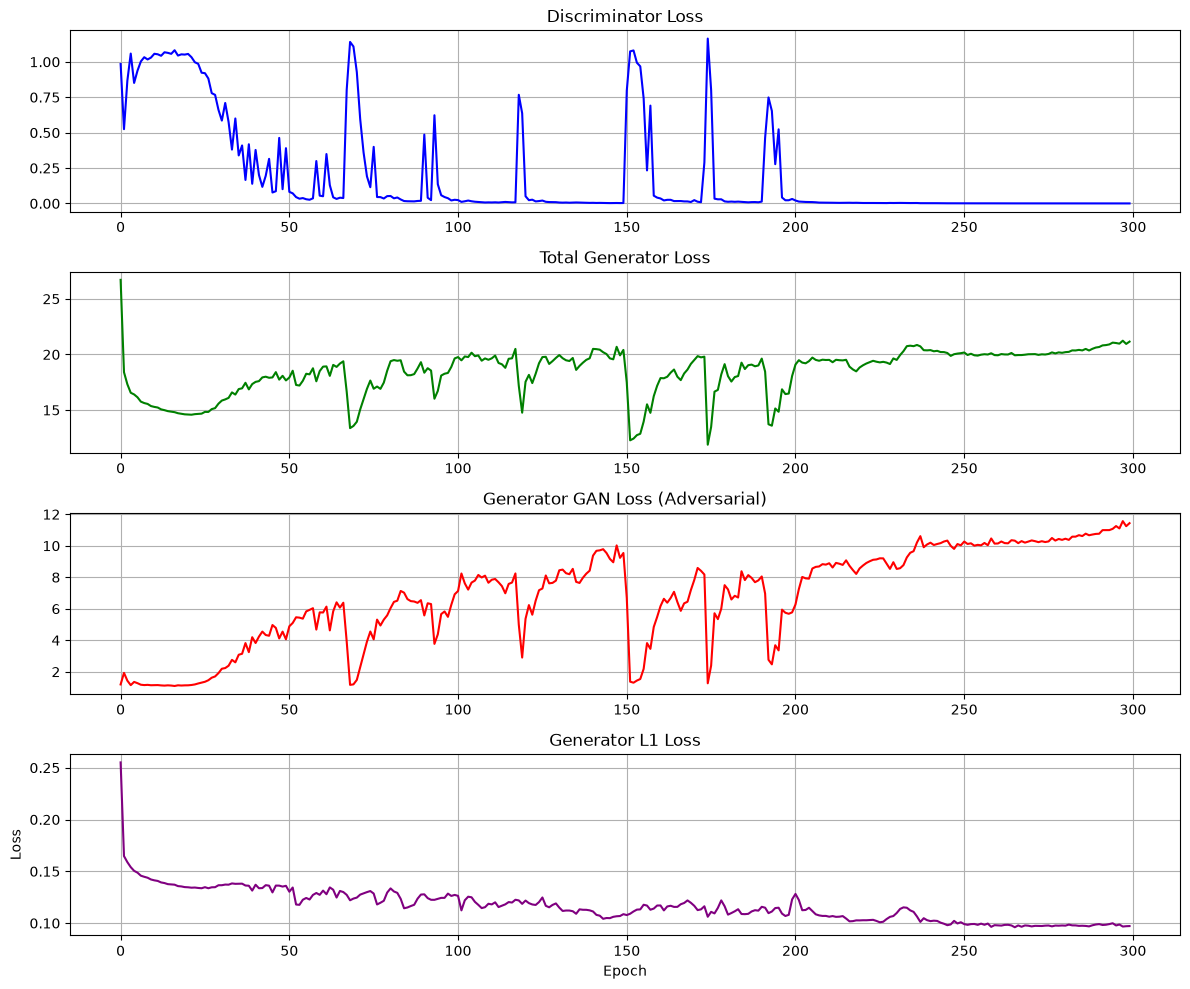

In [19]:
fig, axs = plt.subplots(4, 1, figsize=(12, 10))

axs[0].plot(disc_loss, color='blue')
axs[0].set_title('Discriminator Loss')
axs[0].grid(True)

axs[1].plot(gen_total_loss, color='green')
axs[1].set_title('Total Generator Loss')
axs[1].grid(True)

axs[2].plot(gen_gan_loss, color='red')
axs[2].set_title('Generator GAN Loss (Adversarial)')
axs[2].grid(True)

axs[3].plot(gen_l1_loss, color='purple')
axs[3].set_title('Generator L1 Loss')
axs[3].set_xlabel('Epoch')
axs[3].set_ylabel('Loss')
axs[3].grid(True)

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 827ms/step


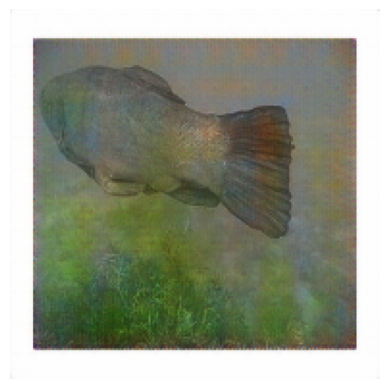

In [20]:
for input_image, target in train_generator.take(1):
    sample_input = input_image[0:1]

    predicted_image = generator.predict(sample_input)

    plt.imshow((predicted_image[0] + 1) / 2.0)
    plt.axis('off')
    plt.show()

In [21]:
generator.save('generator.keras')